In [1]:
# Install TensorFlow Datasets for loading the PASCAL VOC dataset
!pip install -q tensorflow-datasets==4.9.10

# Install a compatible version of TensorFlow Metadata
!pip install -q tensorflow-metadata==1.17.3

# Restore Protobuf to version 5.29.5
!pip install -q protobuf==5.29.5

In [5]:
# Install Ultralytics for YOLO26 model training and evaluation
!pip install -q ultralytics

# 1. Import Librarires

In [6]:
# Dataset loading
import tensorflow_datasets as tfds

# Data processing and analysis
import numpy as np
import pandas as pd
import random
from collections import Counter

# Image processing and visualization
import matplotlib.pyplot as plt
from PIL import Image

# File and directory management
import os
import shutil
from pathlib import Path

# YOLO26 model
from ultralytics import YOLO

# Configuration files
import yaml

# Confirm successful imports
print("All libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
All libraries imported successfully!


In [9]:
# Set random seeds for reproducible results
random.seed(42)
np.random.seed(42)

print("Random seeds configured successfully!")

Random seeds configured successfully!


# 2. DataSet 

## 2.1 Identify the dataset

In [3]:
# Access the PASCAL VOC 2007 dataset using TensorFlow Datasets
builder = tfds.builder('voc/2007')

# Display the dataset name and version
print("Dataset name:", builder.info.name)
print("Dataset version:", builder.info.version)

# Display the available dataset splits (training, validation, and test)
print("\nAvailable dataset splits:")
print(builder.info.splits)

# Display the 20 object classes available in PASCAL VOC
print("\nObject classes:")
print(builder.info.features['objects']['label'].names)

# Display general information about the dataset
print("\nDataset information:")
print(builder.info)

Dataset name: voc
Dataset version: 5.0.0

Available dataset splits:
{}

Object classes:
['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']

Dataset information:
tfds.core.DatasetInfo(
    name='voc',
    full_name='voc/2007/5.0.0',
    description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge,
    corresponding to the Classification and Detection competitions.
    
    In the Classification competition, the goal is to predict the set of labels
    contained in the image, while in the Detection competition the goal is to
    predict the bounding box and label of each individual object.
    annotations.
    """,
    config_description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge
    2007, a.k.a. VOC2007.
    
    A total of 9963 images are included in this dataset

## 2.2 Download and load the dataset 

In [4]:
# Load the PASCAL VOC 2007 dataset and retrieve its information
datasets, info = tfds.load(
    'voc/2007',
    with_info=True,
    shuffle_files=False
)

# Confirm that the dataset has been loaded
print("PASCAL VOC 2007 loaded successfully!")

# Display the available dataset splits
print("\nAvailable dataset splits:")

for split_name, split_info in info.splits.items():
    # Display the number of images in each split
    print(split_name, ":", split_info.num_examples, "images")

# Display the dataset storage location
print("\nDataset location:")
print(info.data_dir)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2007/incomplete.VM4OEG_5.0.0/voc-test.tfrecord-[0-9][0-9][0-9][0-9][0-…

... (2 outputs left out)

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2007/incomplete.VM4OEG_5.0.0/voc-validation.tfrecord-[0-9][0-9][0-9][0…

Dataset voc downloaded and prepared to /root/tensorflow_datasets/voc/2007/5.0.0. Subsequent calls will reuse this data.
PASCAL VOC 2007 loaded successfully!

Available dataset splits:
test : 4952 images
train : 2501 images
validation : 2510 images

Dataset location:
/root/tensorflow_datasets/voc/2007/5.0.0


I0000 00:00:1793555796.911223      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793555796.914054      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [10]:
# Check whether the VOC dataset is still loaded
if 'datasets' in globals():
    print("PASCAL VOC dataset is available!")
    print("Available splits:", list(datasets.keys()))
else:
    print("Dataset is not currently loaded. We need to load it again.")

PASCAL VOC dataset is available!
Available splits: [Split('test'), Split('train'), Split('validation')]


# 3 EDA

## ****3.1. Visualize images with bounding boxes

In [13]:
# Display the available dataset splits
print("Available splits:", list(datasets.keys()))

# Access the training dataset
train_dataset = datasets['train']

# Select the first image from the training dataset
sample = next(iter(train_dataset))

# Display the structure of the selected sample
print("\nSample structure:")
print(sample.keys())

# Display the image dimensions (height, width, channels)
print("\nImage shape:")
print(sample['image'].shape)

# Display the image data type
print("\nImage data type:")
print(sample['image'].dtype)

# Display the available annotation fields
print("\nObject annotation fields:")
print(sample['objects'].keys())

# Count the number of objects in this image
print("\nNumber of objects in this image:")
print(len(sample['objects']['label']))

# Display the numerical IDs of the object classes
print("\nObject class IDs:")
print(sample['objects']['label'].numpy())

# Get the names corresponding to the class IDs
class_names = info.features['objects']['label'].names

# Display the object class names
print("\nObject class names:")
print([
    class_names[int(label)]
    for label in sample['objects']['label'].numpy()
])


Available splits: [Split('test'), Split('train'), Split('validation')]

Sample structure:
dict_keys(['image', 'image/filename', 'labels', 'labels_no_difficult', 'objects'])

Image shape:
(480, 389, 3)

Image data type:
<dtype: 'uint8'>

Object annotation fields:
dict_keys(['bbox', 'is_difficult', 'is_truncated', 'label', 'pose'])

Number of objects in this image:
4

Object class IDs:
[12 14 12 14]

Object class names:
['horse', 'person', 'horse', 'person']


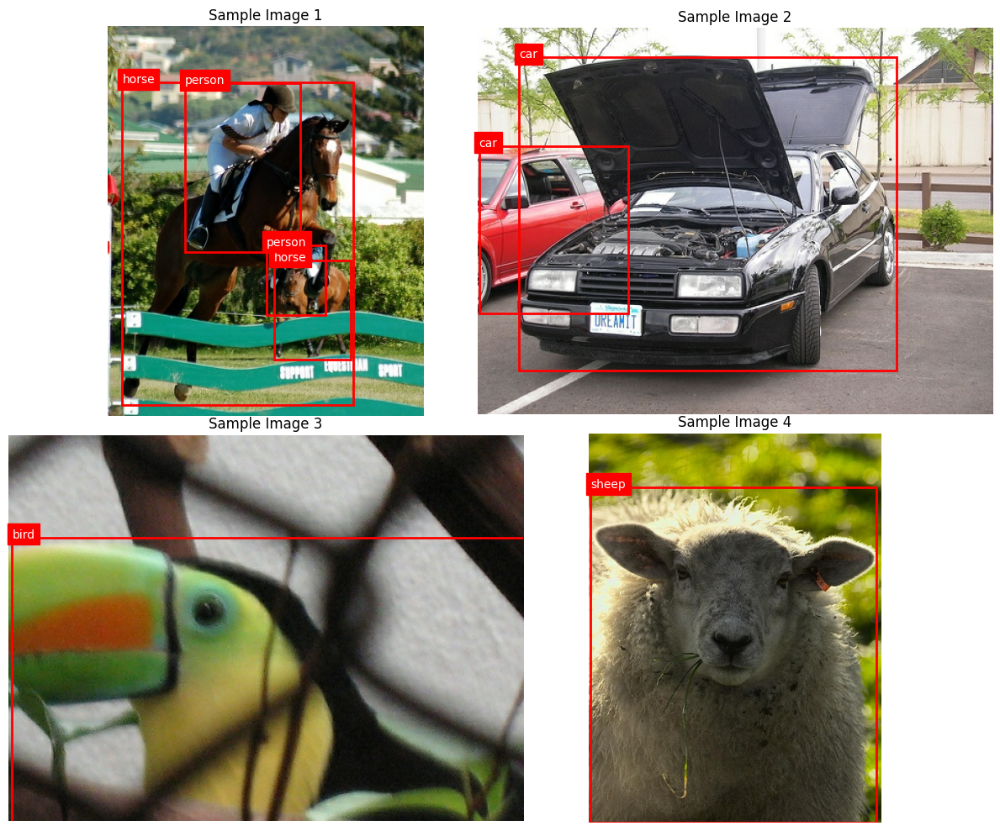

In [14]:
# Get the object class names
class_names = info.features['objects']['label'].names

# Get 4 images from the training dataset
samples = list(train_dataset.take(4))

# Create a figure to display the 4 images
plt.figure(figsize=(12, 10))

# Loop through the selected images
for i, sample in enumerate(samples):

    # Get the image and its annotations
    image = sample['image'].numpy()
    boxes = sample['objects']['bbox'].numpy()
    labels = sample['objects']['label'].numpy()

    # Get image dimensions
    height, width, _ = image.shape

    # Create a subplot
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)

    # Draw bounding boxes around objects
    for box, label in zip(boxes, labels):
        y_min, x_min, y_max, x_max = box

        rectangle = plt.Rectangle(
            (x_min * width, y_min * height),
            (x_max - x_min) * width,
            (y_max - y_min) * height,
            fill=False,
            edgecolor='red',
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        # Display the object class
        plt.text(
            x_min * width,
            y_min * height,
            class_names[int(label)],
            color='white',
            backgroundcolor='red'
        )

    # Add image number
    plt.title(f"Sample Image {i + 1}")
    plt.axis('off')

# Adjust the spacing between images
plt.tight_layout()

# Display all 4 images
plt.show()

## 3.2. Analyze Class Distribution

In [71]:
# Create a counter for all 20 object classes
class_counts = np.zeros(20, dtype=int)

# Count the objects in each training image
for sample in train_dataset:
    labels = sample['objects']['label'].numpy()

    # Add the number of occurrences of each class
    for label in labels:
        class_counts[int(label)] += 1

# Get the object class names
class_names = info.features['objects']['label'].names

# Display the number of objects in each class
for name, count in zip(class_names, class_counts):
    print(name, ":", count)

# Display the total number of annotated objects
print("\nTotal objects:", class_counts.sum())

aeroplane : 156
bicycle : 202
bird : 294
boat : 208
bottle : 338
bus : 131
car : 826
cat : 191
chair : 726
cow : 185
diningtable : 148
dog : 271
horse : 207
motorbike : 193
person : 2705
pottedplant : 305
sheep : 191
sofa : 218
train : 158
tvmonitor : 191

Total objects: 7844


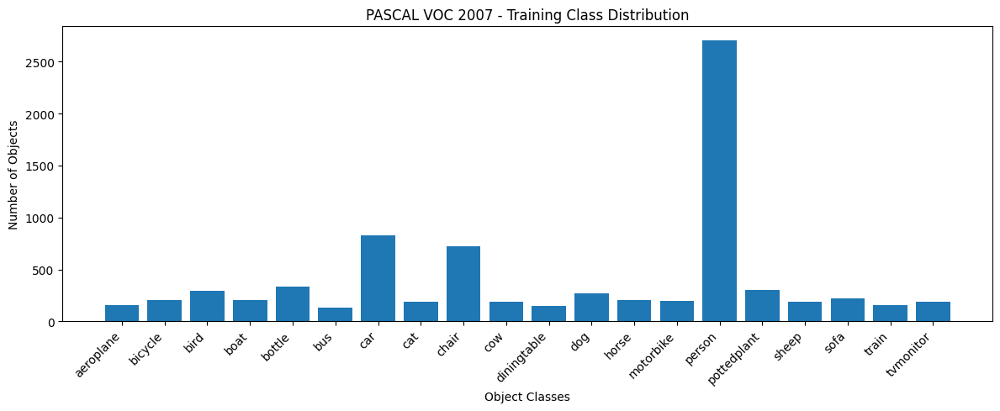

In [72]:
# Create a bar chart of the object class distribution
plt.figure(figsize=(12, 5))

# Plot the number of objects in each class
plt.bar(class_names, class_counts)

# Add chart labels and title
plt.title("PASCAL VOC 2007 - Training Class Distribution")
plt.xlabel("Object Classes")
plt.ylabel("Number of Objects")

# Rotate class names to make them readable
plt.xticks(rotation=45, ha='right')

# Display the chart
plt.tight_layout()
plt.show()

## 3.3. Analyze the number of objects per image

In [73]:
# Create a list to store the number of objects in each image
object_counts = []

# Count the objects in every training image
for sample in train_dataset:
    object_counts.append(len(sample['objects']['label']))

# Convert the counts into a NumPy array
object_counts = np.array(object_counts)

# Display basic statistics
print("Total training images:", len(object_counts))
print("Average objects per image:", round(object_counts.mean(), 2))
print("Minimum objects in an image:", object_counts.min())
print("Maximum objects in an image:", object_counts.max())

# Count images containing exactly one object
print("Images with one object:", np.sum(object_counts == 1))

# Count images containing more than one object
print("Images with multiple objects:", np.sum(object_counts > 1))

Total training images: 2501
Average objects per image: 3.14
Minimum objects in an image: 1
Maximum objects in an image: 37
Images with one object: 905
Images with multiple objects: 1596


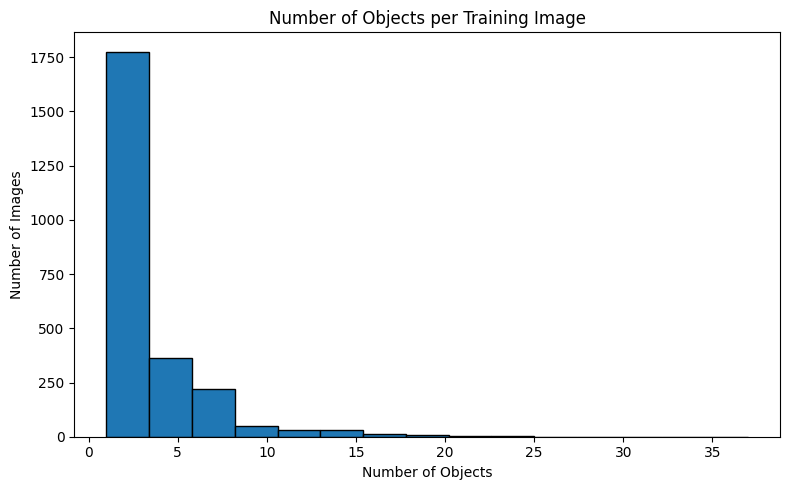

In [74]:
# Create a histogram of the number of objects per image
plt.figure(figsize=(8, 5))

# Display the distribution
plt.hist(object_counts, bins=15, edgecolor='black')

# Add chart labels and title
plt.title("Number of Objects per Training Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

# Display the chart
plt.tight_layout()
plt.show()

## 3.4. Analyze image dimensions

In [75]:
# Create lists to store image widths and heights
widths = []
heights = []

# Get the dimensions of each training image
for sample in train_dataset:
    height, width, channels = sample['image'].shape

    widths.append(width)
    heights.append(height)

# Convert the lists into NumPy arrays
widths = np.array(widths)
heights = np.array(heights)

# Display image dimension statistics
print("Minimum width:", widths.min())
print("Maximum width:", widths.max())
print("Average width:", round(widths.mean(), 2))

print("\nMinimum height:", heights.min())
print("Maximum height:", heights.max())
print("Average height:", round(heights.mean(), 2))

# Check how many different image dimensions exist
print("\nNumber of unique widths:", len(np.unique(widths)))
print("Number of unique heights:", len(np.unique(heights)))

Minimum width: 127
Maximum width: 500
Average width: 471.98

Minimum height: 96
Maximum height: 500
Average height: 383.87

Number of unique widths: 115
Number of unique heights: 198


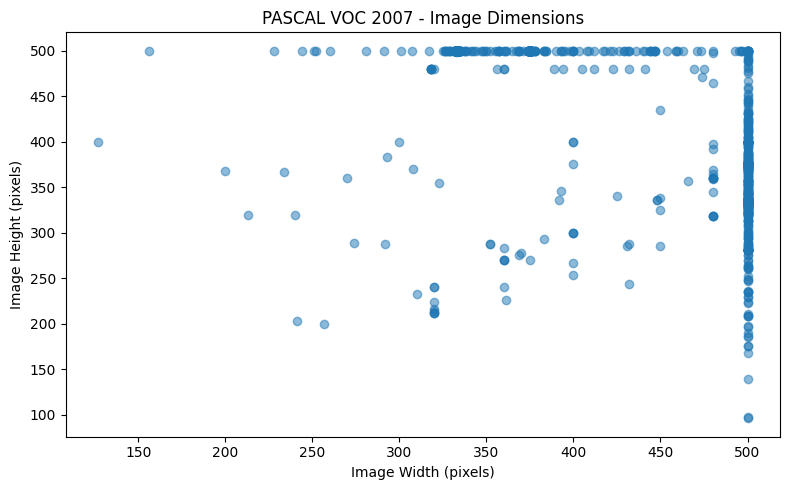

In [76]:
# Create a scatter plot of image dimensions
plt.figure(figsize=(8, 5))

# Plot width against height
plt.scatter(widths, heights, alpha=0.5)

# Add chart labels and title
plt.title("PASCAL VOC 2007 - Image Dimensions")
plt.xlabel("Image Width (pixels)")
plt.ylabel("Image Height (pixels)")

# Display the chart
plt.tight_layout()
plt.show()

## 3.5. Analyze bounding-box sizes

In [77]:
# Create lists to store bounding-box measurements
box_widths = []
box_heights = []
box_areas = []

# Analyze bounding boxes in each training image
for sample in train_dataset:

    # Get the normalized bounding-box coordinates
    boxes = sample['objects']['bbox'].numpy()

    # Calculate the width, height, and area of each box
    for box in boxes:
        y_min, x_min, y_max, x_max = box

        width = x_max - x_min
        height = y_max - y_min
        area = width * height

        box_widths.append(width)
        box_heights.append(height)
        box_areas.append(area)

# Convert measurements into NumPy arrays
box_widths = np.array(box_widths)
box_heights = np.array(box_heights)
box_areas = np.array(box_areas)

# Display bounding-box statistics
print("Total bounding boxes:", len(box_areas))

print("\nBounding-box width:")
print("Minimum:", round(box_widths.min(), 4))
print("Maximum:", round(box_widths.max(), 4))
print("Average:", round(box_widths.mean(), 4))

print("\nBounding-box height:")
print("Minimum:", round(box_heights.min(), 4))
print("Maximum:", round(box_heights.max(), 4))
print("Average:", round(box_heights.mean(), 4))

print("\nBounding-box area:")
print("Minimum:", round(box_areas.min(), 4))
print("Maximum:", round(box_areas.max(), 4))
print("Average:", round(box_areas.mean(), 4))

Total bounding boxes: 7844

Bounding-box width:
Minimum: 0.008
Maximum: 0.998
Average: 0.3033

Bounding-box height:
Minimum: 0.012
Maximum: 0.998
Average: 0.3926

Bounding-box area:
Minimum: 0.0003
Maximum: 0.9953
Average: 0.1683


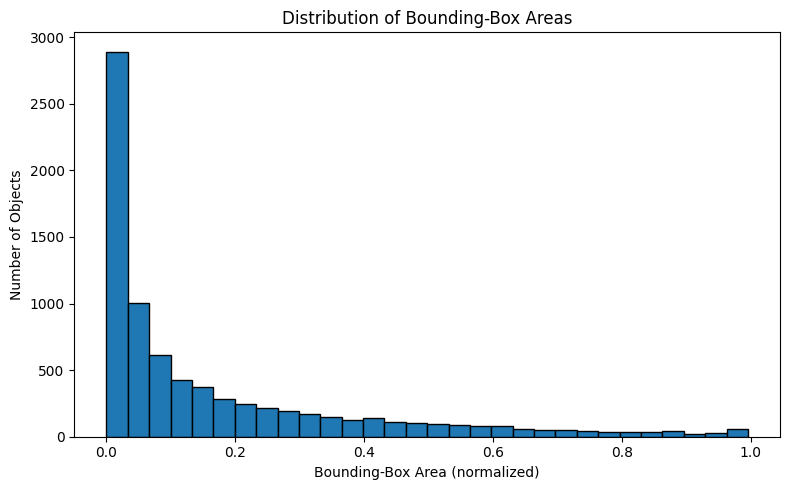

In [78]:
# Create a histogram of bounding-box areas
plt.figure(figsize=(8, 5))

# Display the distribution of bounding-box areas
plt.hist(box_areas, bins=30, edgecolor='black')

# Add chart labels and title
plt.title("Distribution of Bounding-Box Areas")
plt.xlabel("Bounding-Box Area (normalized)")
plt.ylabel("Number of Objects")

# Display the chart
plt.tight_layout()
plt.show()

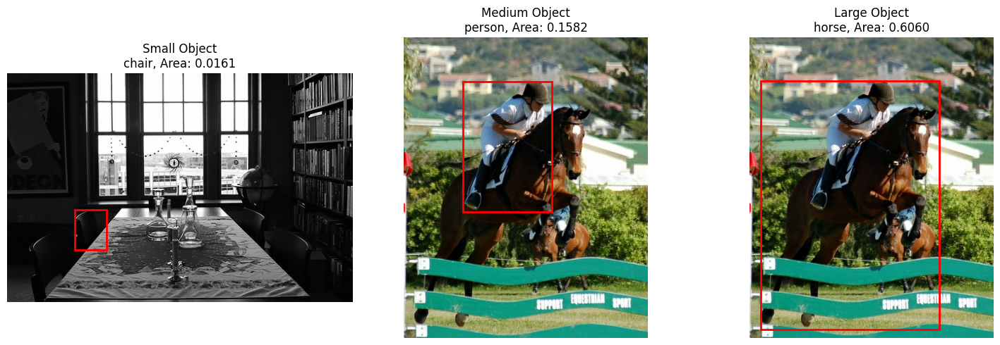

In [79]:
# Store one example for each bounding-box size category
examples = {
    "Small": None,
    "Medium": None,
    "Large": None
}

# Search the training dataset for suitable examples
for sample in train_dataset:

    # Get the image and its bounding boxes
    image = sample['image'].numpy()
    boxes = sample['objects']['bbox'].numpy()
    labels = sample['objects']['label'].numpy()

    # Check each object in the image
    for box, label in zip(boxes, labels):

        # Calculate the bounding-box area
        y_min, x_min, y_max, x_max = box
        area = (y_max - y_min) * (x_max - x_min)

        # Select the first example matching each category
        if area < 0.02 and examples["Small"] is None:
            examples["Small"] = (image, box, label, area)

        elif 0.02 <= area <= 0.20 and examples["Medium"] is None:
            examples["Medium"] = (image, box, label, area)

        elif area > 0.20 and examples["Large"] is None:
            examples["Large"] = (image, box, label, area)

    # Stop when all three examples have been found
    if all(value is not None for value in examples.values()):
        break

# Display the selected examples
plt.figure(figsize=(15, 5))

for i, (category, example) in enumerate(examples.items()):

    # Get the selected image and object information
    image, box, label, area = example
    height, width, _ = image.shape
    y_min, x_min, y_max, x_max = box

    # Display the image
    plt.subplot(1, 3, i + 1)
    plt.imshow(image)

    # Draw the selected object's bounding box
    rectangle = plt.Rectangle(
        (x_min * width, y_min * height),
        (x_max - x_min) * width,
        (y_max - y_min) * height,
        fill=False,
        edgecolor='red',
        linewidth=2
    )

    plt.gca().add_patch(rectangle)

    # Display the object class and area
    plt.title(
        f"{category} Object\n"
        f"{class_names[int(label)]}, Area: {area:.4f}"
    )

    plt.axis('off')

# Adjust spacing and display the examples
plt.tight_layout()
plt.show()

## 3.6. Analyze difficult and truncated objects

In [80]:
# Initialize counters for difficult and truncated objects
difficult_count = 0
truncated_count = 0
total_objects = 0

# Check annotations in every training image
for sample in train_dataset:

    # Get the object annotation flags
    difficult = sample['objects']['is_difficult'].numpy()
    truncated = sample['objects']['is_truncated'].numpy()

    # Count all annotated objects
    total_objects += len(difficult)

    # Count difficult and truncated objects
    difficult_count += np.sum(difficult)
    truncated_count += np.sum(truncated)

# Display the results
print("Total objects:", total_objects)

print("\nDifficult objects:", difficult_count)
print("Percentage:", round(difficult_count / total_objects * 100, 2), "%")

print("\nTruncated objects:", truncated_count)
print("Percentage:", round(truncated_count / total_objects * 100, 2), "%")

Total objects: 7844

Difficult objects: 1543
Percentage: 19.67 %

Truncated objects: 4108
Percentage: 52.37 %


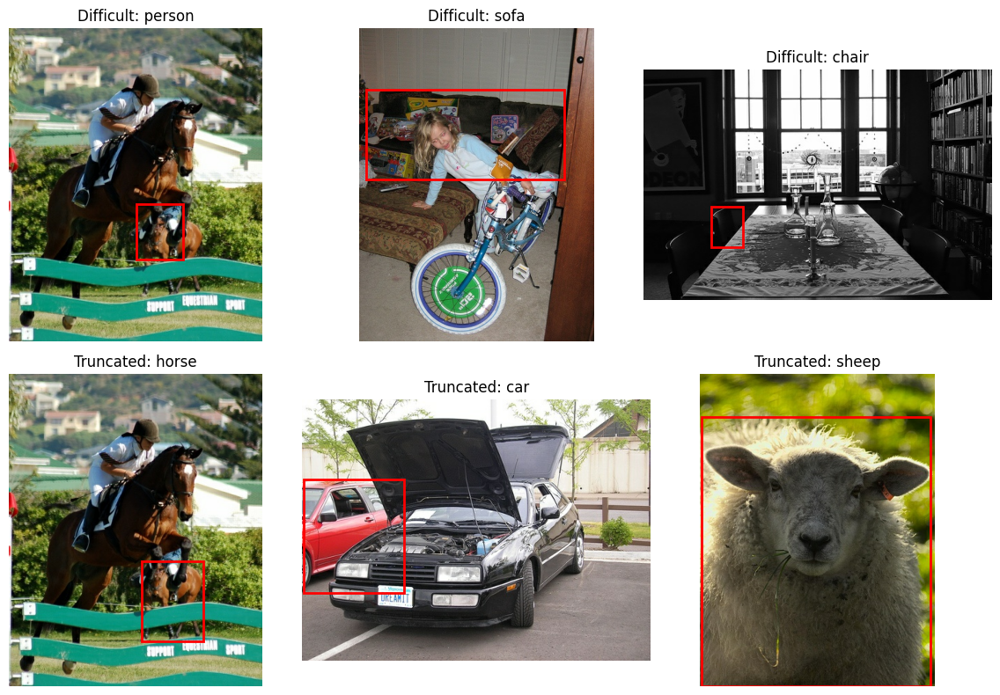

In [81]:
# Store 3 examples of each annotation type
examples = {
    "Difficult": [],
    "Truncated": []
}

# Search the training dataset for examples
for sample in train_dataset:

    # Get the image and object annotations
    image = sample['image'].numpy()
    boxes = sample['objects']['bbox'].numpy()
    labels = sample['objects']['label'].numpy()
    difficult = sample['objects']['is_difficult'].numpy()
    truncated = sample['objects']['is_truncated'].numpy()

    # Find one difficult object in this image
    if len(examples["Difficult"]) < 3:
        for box, label, flag in zip(boxes, labels, difficult):
            if flag:
                examples["Difficult"].append((image, box, label))
                break

    # Find one truncated object in this image
    if len(examples["Truncated"]) < 3:
        for box, label, flag in zip(boxes, labels, truncated):
            if flag:
                examples["Truncated"].append((image, box, label))
                break

    # Stop when 3 different images are found for each category
    if (len(examples["Difficult"]) == 3 and
            len(examples["Truncated"]) == 3):
        break

# Display the selected examples
plt.figure(figsize=(12, 8))

for i, category in enumerate(["Difficult", "Truncated"]):

    for j, example in enumerate(examples[category]):

        # Get the image and object information
        image, box, label = example
        height, width, _ = image.shape
        y_min, x_min, y_max, x_max = box

        # Display the image
        plt.subplot(2, 3, i * 3 + j + 1)
        plt.imshow(image)

        # Draw the selected bounding box
        rectangle = plt.Rectangle(
            (x_min * width, y_min * height),
            (x_max - x_min) * width,
            (y_max - y_min) * height,
            fill=False,
            edgecolor='red',
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        # Display the category and object class
        plt.title(f"{category}: {class_names[int(label)]}")
        plt.axis('off')

# Adjust spacing and display the examples
plt.tight_layout()
plt.show()

## 3.7. Select a small, reproducible dataset subset

In [15]:
# Set a fixed random seed for reproducibility
random.seed(42)

# Select 300 training images
train_subset = list(train_dataset.shuffle(
    buffer_size=2501,
    seed=42,
    reshuffle_each_iteration=False
).take(300))

# Select 100 validation images
validation_dataset = datasets['validation']

validation_subset = list(validation_dataset.shuffle(
    buffer_size=2510,
    seed=42,
    reshuffle_each_iteration=False
).take(100))

# Display the selected dataset sizes
print("Training subset:", len(train_subset))
print("Validation subset:", len(validation_subset))
print("Total selected images:", len(train_subset) + len(validation_subset))

Training subset: 300
Validation subset: 100
Total selected images: 400


In [16]:
# Create counters for training and validation classes
train_class_counts = np.zeros(20, dtype=int)
validation_class_counts = np.zeros(20, dtype=int)

# Count objects in the training subset
for sample in train_subset:
    labels = sample['objects']['label'].numpy()

    for label in labels:
        train_class_counts[int(label)] += 1

# Count objects in the validation subset
for sample in validation_subset:
    labels = sample['objects']['label'].numpy()

    for label in labels:
        validation_class_counts[int(label)] += 1

# Display class distribution
print("Class distribution in selected datasets:\n")

for i, name in enumerate(class_names):
    print(
        name,
        "| Training:", train_class_counts[i],
        "| Validation:", validation_class_counts[i]
    )

# Count classes missing from either split
print("\nClasses missing from training:",
      np.sum(train_class_counts == 0))

print("Classes missing from validation:",
      np.sum(validation_class_counts == 0))

Class distribution in selected datasets:

aeroplane | Training: 12 | Validation: 7
bicycle | Training: 27 | Validation: 11
bird | Training: 29 | Validation: 17
boat | Training: 36 | Validation: 18
bottle | Training: 45 | Validation: 15
bus | Training: 15 | Validation: 1
car | Training: 85 | Validation: 14
cat | Training: 21 | Validation: 8
chair | Training: 73 | Validation: 40
cow | Training: 19 | Validation: 19
diningtable | Training: 25 | Validation: 16
dog | Training: 40 | Validation: 7
horse | Training: 25 | Validation: 4
motorbike | Training: 28 | Validation: 4
person | Training: 351 | Validation: 114
pottedplant | Training: 16 | Validation: 17
sheep | Training: 27 | Validation: 2
sofa | Training: 27 | Validation: 11
train | Training: 17 | Validation: 4
tvmonitor | Training: 21 | Validation: 5

Classes missing from training: 0
Classes missing from validation: 0


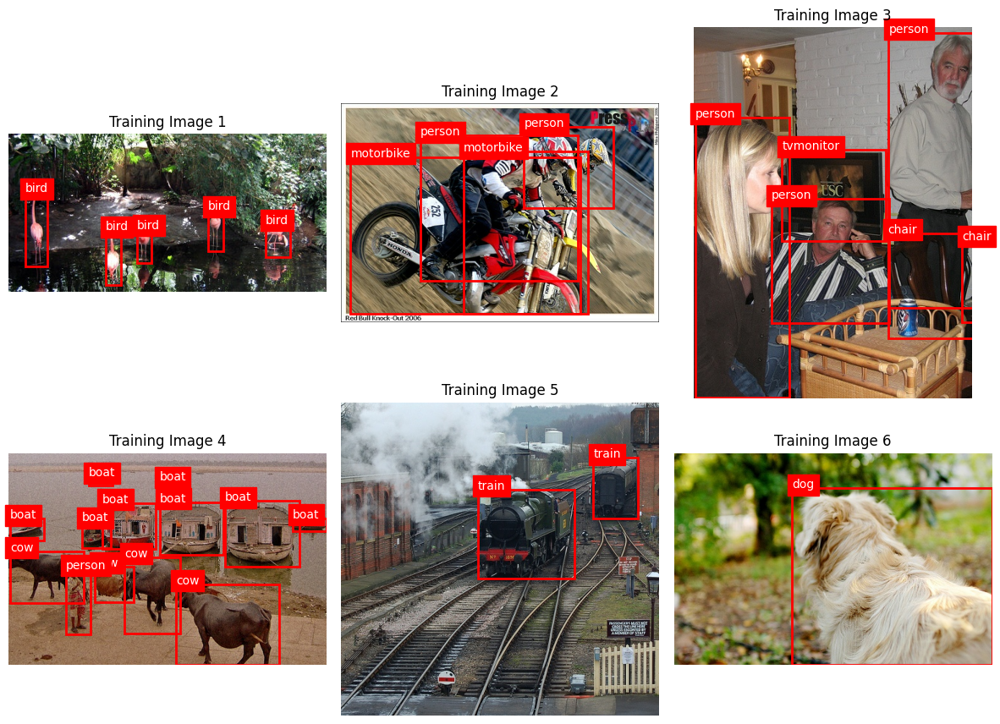

In [17]:
# Visualize the selected dataset
# Select 6 images from the training subset
samples = train_subset[:6]

# Create a figure for displaying the images
plt.figure(figsize=(12, 9))

# Display each selected image
for i, sample in enumerate(samples):

    # Get the image and its annotations
    image = sample['image'].numpy()
    boxes = sample['objects']['bbox'].numpy()
    labels = sample['objects']['label'].numpy()

    # Get image dimensions
    height, width, _ = image.shape

    # Create a subplot
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)

    # Draw bounding boxes around objects
    for box, label in zip(boxes, labels):
        y_min, x_min, y_max, x_max = box

        rectangle = plt.Rectangle(
            (x_min * width, y_min * height),
            (x_max - x_min) * width,
            (y_max - y_min) * height,
            fill=False,
            edgecolor='red',
            linewidth=2
        )

        plt.gca().add_patch(rectangle)

        # Display the object class
        plt.text(
            x_min * width,
            y_min * height,
            class_names[int(label)],
            color='white',
            backgroundcolor='red'
        )

    # Add image number
    plt.title(f"Training Image {i + 1}")
    plt.axis('off')

# Adjust spacing and display the images
plt.tight_layout()
plt.show()

# 4. Convert PASCAL VOC to YOLO format

#### Section 5: Convert PASCAL VOC to YOLO format

5.1 Check variables
5.2 Create folders
5.3 Test conversion on one image
5.5 Visualize bounding boxes
5.6 Convert and save all 400 images
5.7 Create data.yaml

In [18]:
# Check that the selected subsets are available
required_variables = ['train_subset', 'validation_subset']
missing = [name for name in required_variables if name not in globals()]

if missing:
    print("Missing variables:", missing)
    print("We need to rerun EDA Step 7.")
else:
    print("Training images:", len(train_subset))
    print("Validation images:", len(validation_subset))

Training images: 300
Validation images: 100


In [19]:
# Create the YOLO dataset folders
# Define the YOLO dataset directory structure
dataset_path = Path("voc_yolo")

for split in ["train", "val"]:
    (dataset_path / "images" / split).mkdir(parents=True, exist_ok=True)
    (dataset_path / "labels" / split).mkdir(parents=True, exist_ok=True)

print("YOLO dataset folders created successfully!")

YOLO dataset folders created successfully!


In [20]:
# Test the conversion on one image
# Get one training image and its annotations
sample = train_subset[0]

image_height, image_width = sample['image'].shape[:2]
boxes = sample['objects']['bbox'].numpy()
labels = sample['objects']['label'].numpy()

# Convert bounding boxes to YOLO format
for box, label in zip(boxes, labels):
    y_min, x_min, y_max, x_max = box

    x_center = (x_min + x_max) / 2
    y_center = (y_min + y_max) / 2
    box_width = x_max - x_min
    box_height = y_max - y_min

    print(
        int(label),
        round(float(x_center), 4),
        round(float(y_center), 4),
        round(float(box_width), 4),
        round(float(box_height), 4)
    )

2 0.087 0.6028 0.07 0.4718
2 0.329 0.7823 0.05 0.3468
2 0.847 0.6754 0.078 0.2137
2 0.426 0.7097 0.044 0.2177
2 0.651 0.6109 0.05 0.2621


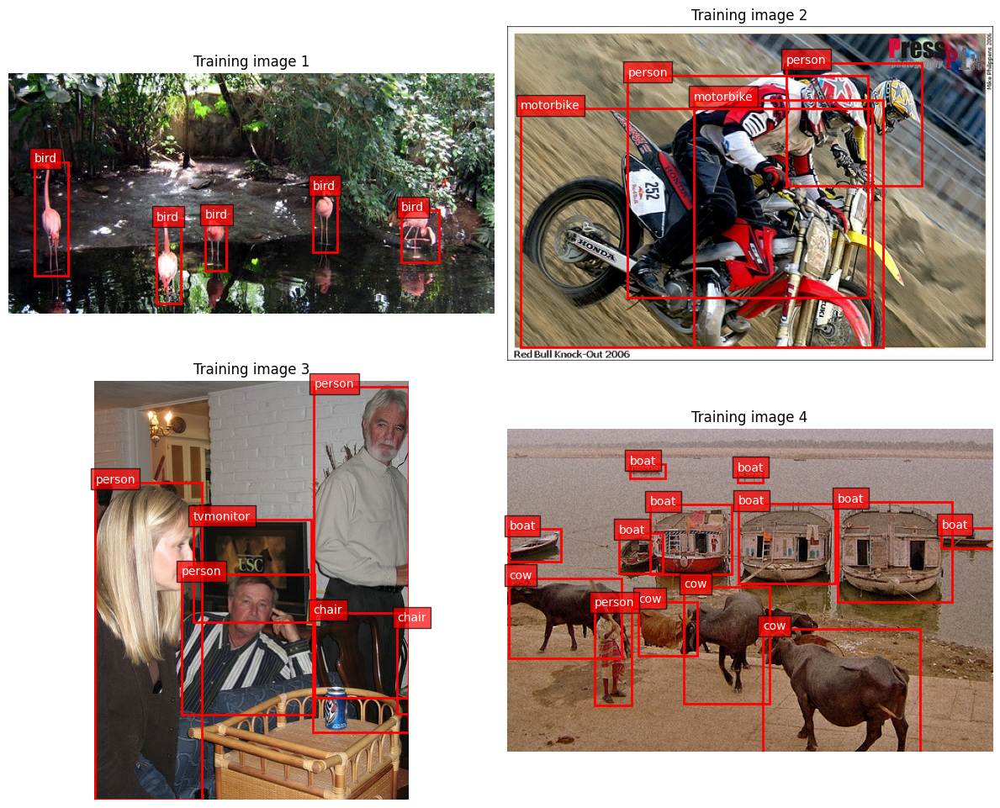

In [21]:
# Visualize the converted YOLO annotations
# Display 4 training images with bounding boxes and class names
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, ax in enumerate(axes.flat):
    sample = train_subset[i]
    image = sample['image'].numpy()
    height, width = image.shape[:2]

    ax.imshow(image)

    for box, label in zip(
        sample['objects']['bbox'].numpy(),
        sample['objects']['label'].numpy()
    ):
        y_min, x_min, y_max, x_max = box

        x1, y1 = float(x_min) * width, float(y_min) * height
        x2, y2 = float(x_max) * width, float(y_max) * height

        ax.add_patch(plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor='red', linewidth=2
        ))

        ax.text(
            x1, y1, class_names[int(label)],
            color='white',
            bbox=dict(facecolor='red', alpha=0.7)
        )

    ax.set_title(f"Training image {i + 1}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [22]:
# Convert and save images and annotations in YOLO format
def save_yolo_data(samples, split):
    for i, sample in enumerate(samples):
        image = sample['image'].numpy()
        height, width = image.shape[:2]

        image_path = dataset_path / "images" / split / f"{i}.jpg"
        label_path = dataset_path / "labels" / split / f"{i}.txt"

        Image.fromarray(image).save(image_path)

        boxes = sample['objects']['bbox'].numpy()
        labels = sample['objects']['label'].numpy()

        with open(label_path, 'w') as f:
            for box, label in zip(boxes, labels):
                y_min, x_min, y_max, x_max = box

                x_center = (x_min + x_max) / 2
                y_center = (y_min + y_max) / 2
                box_width = x_max - x_min
                box_height = y_max - y_min

                f.write(
                    f"{int(label)} "
                    f"{x_center:.6f} {y_center:.6f} "
                    f"{box_width:.6f} {box_height:.6f}\n"
                )

save_yolo_data(train_subset, "train")
save_yolo_data(validation_subset, "val")

print("Training images saved:", len(list((dataset_path / "images/train").glob("*.jpg"))))
print("Validation images saved:", len(list((dataset_path / "images/val").glob("*.jpg"))))
print("Dataset conversion completed!")

Training images saved: 300
Validation images saved: 100
Dataset conversion completed!


In [23]:
# Create YOLO dataset configuration
data_config = {
    'path': str(dataset_path.resolve()),
    'train': 'images/train',
    'val': 'images/val',
    'nc': len(class_names),
    'names': class_names
}

with open(dataset_path / 'data.yaml', 'w') as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("data.yaml created successfully!")

data.yaml created successfully!


In [24]:
# Verify the generated YOLO dataset
train_images = list((dataset_path / "images/train").glob("*.jpg"))
val_images = list((dataset_path / "images/val").glob("*.jpg"))

train_labels = list((dataset_path / "labels/train").glob("*.txt"))
val_labels = list((dataset_path / "labels/val").glob("*.txt"))

print("Training images:", len(train_images))
print("Training labels:", len(train_labels))
print("Validation images:", len(val_images))
print("Validation labels:", len(val_labels))

print("\nDataset configuration:")
print(yaml.safe_load(open(dataset_path / "data.yaml")))

Training images: 300
Training labels: 300
Validation images: 100
Validation labels: 100

Dataset configuration:
{'path': '/kaggle/working/voc_yolo', 'train': 'images/train', 'val': 'images/val', 'nc': 20, 'names': ['aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']}


# 5. Train YOLO26n

### 5.1 Load YOLO26n pretrained model


In [25]:
# Load pretrained YOLO26n model using the Ultralytics library
model = YOLO("yolo26n.pt")

print("YOLO26n model loaded successfully!")

YOLO26n model loaded successfully!


### 5.2 Configure training parameters

In [26]:
# Configure YOLO26n training parameters
epochs = 50
imgsz = 640
batch_size = 16

print("Training parameters configured!")
print("Epochs:", epochs)
print("Image size:", imgsz)
print("Batch size:", batch_size)

Training parameters configured!
Epochs: 50
Image size: 640
Batch size: 16


### 5.3 Train YOLO26n

In [27]:
# Check GPU availability
import torch

print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [28]:
# Train YOLO26n on the PASCAL VOC dataset
results = model.train(
    data=str(dataset_path / "data.yaml"),
    epochs=epochs,
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    project="runs",
    name="yolo26n_voc"
)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=voc_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_voc, nbs=64, nms=None, opset=None, optimize=False, optimizer=a

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      3.16G      1.113      2.499    0.01254         88        640: 100% ━━━━━━━━━━━━ 19/19 6.2it/s 3.1s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.2it/s 0.6s0.3s
                   all        100        334      0.805       0.44       0.53      0.381

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      3.16G      1.158      2.071    0.01301         72        640: 100% ━━━━━━━━━━━━ 19/19 6.3it/s 3.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.3it/s 0.6s0.3s
                   all        100        334      0.851      0.393      0.578      0.422

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      3.16G      1.134      1.953    0.01368         66        640: 100% ━━━━━━━━━━━━ 19/19 6.3it/s 3.0s0.2s
                 Class     Images  Instances  

In [30]:
# Find the trained model weights
print("Training output directory:", results.save_dir)

for file in Path(results.save_dir).rglob("*.pt"):
    print("Found model:", file)

Training output directory: /kaggle/working/runs/detect/runs/yolo26n_voc
Found model: /kaggle/working/runs/detect/runs/yolo26n_voc/weights/last.pt
Found model: /kaggle/working/runs/detect/runs/yolo26n_voc/weights/best.pt


### 5.4 Evaluate model performance

In [31]:
# Load the best trained YOLO26n model
best_model = YOLO(str(Path(results.save_dir) / "weights" / "best.pt"))

# Evaluate the model on the validation dataset
metrics = best_model.val(
    data=str(dataset_path / "data.yaml"),
    imgsz=imgsz,
    batch=batch_size,
    device=0
)

print("Model evaluation completed!")
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 881.1±489.5 MB/s, size: 30.5 KB)
val: Scanning /kaggle/working/voc_yolo/labels/val.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 30.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.5it/s 2.0s0.2ss
                   all        100        334      0.753      0.632      0.713      0.513
             aeroplane          7          7      0.999      0.857      0.896       0.69
               bicycle          8         11       0.92          1      0.995      0.735
                  bird         10         17          1      0.452      0.537      0.443
                  boat          9         18      0.776        0.5      0.656      0.423
                bottle          5    

### 5.5 Visualize training results


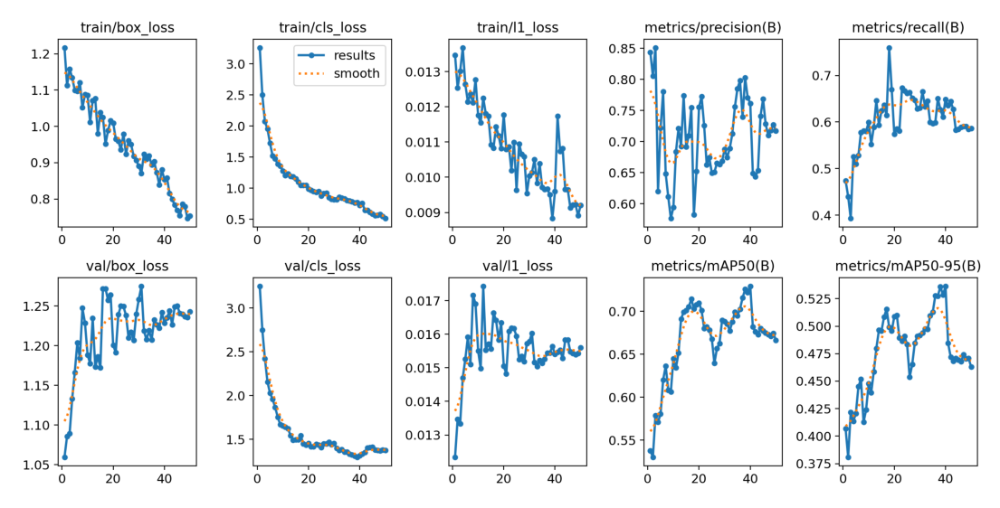

In [32]:
# Display training results
results_image = plt.imread(Path(results.save_dir) / "results.png")

plt.figure(figsize=(14, 10))
plt.imshow(results_image)
plt.axis("off")
plt.show()

### 5.6 Test the trained model on new images



image 1/1 /kaggle/working/voc_test_image.jpg: 448x640 2 chairs, 1 pottedplant, 1 tvmonitor, 10.1ms
Speed: 14.5ms preprocess, 10.1ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)


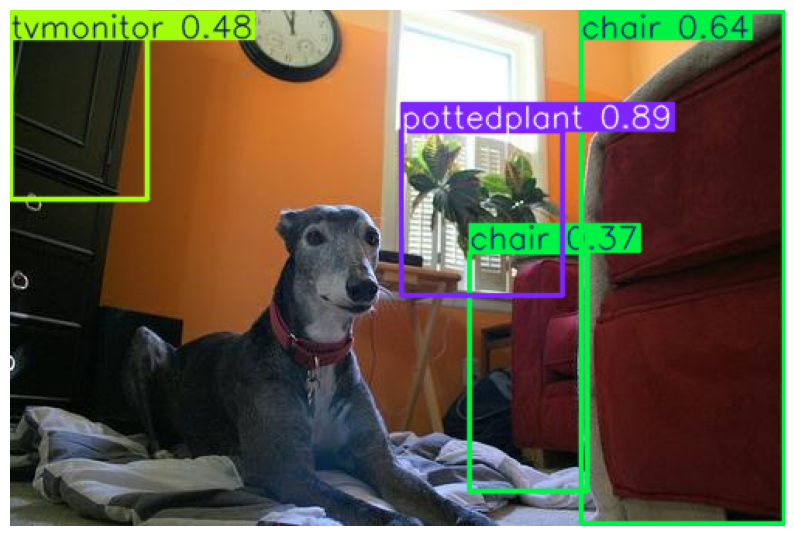

In [33]:
# Select an unseen image from the test dataset
test_sample = next(iter(datasets["test"]))
test_image = test_sample["image"].numpy()

# Save the image
Image.fromarray(test_image).save("voc_test_image.jpg")

# Run object detection
predictions = best_model.predict(
    source="voc_test_image.jpg",
    imgsz=imgsz,
    conf=0.25,
    device=0
)

# Display the detected objects
plt.figure(figsize=(10, 8))
plt.imshow(predictions[0].plot()[..., ::-1])
plt.axis("off")
plt.show()

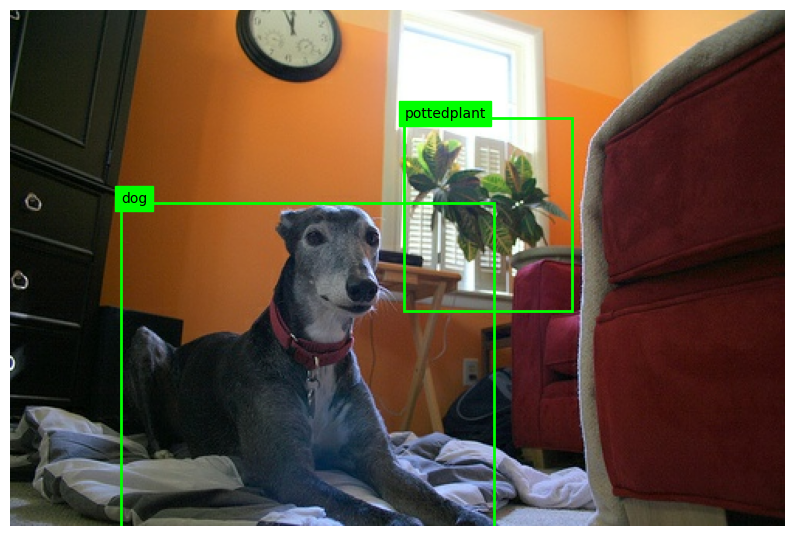

In [34]:
# Display the original image with ground-truth bounding boxes
plt.figure(figsize=(10, 8))
plt.imshow(test_image)

height, width = test_image.shape[:2]
boxes = test_sample["objects"]["bbox"].numpy()
labels = test_sample["objects"]["label"].numpy()

for box, label in zip(boxes, labels):
    y_min, x_min, y_max, x_max = box

    plt.gca().add_patch(plt.Rectangle(
        (x_min * width, y_min * height),
        (x_max - x_min) * width,
        (y_max - y_min) * height,
        fill=False,
        edgecolor="lime",
        linewidth=2
    ))

    plt.text(
        x_min * width,
        y_min * height,
        class_names[int(label)],
        color="black",
        backgroundcolor="lime"
    )

plt.axis("off")
plt.show()

In [35]:
# Display the actual objects annotated in the test image
test_labels = test_sample["objects"]["label"].numpy()

print("Ground-truth objects:")
for label in test_labels:
    print(class_names[int(label)])

Ground-truth objects:
dog
pottedplant


In [36]:
# Display prediction confidence scores
for box in predictions[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        f"Class: {class_names[class_id]}, "
        f"Confidence: {confidence:.2%}"
    )

Class: pottedplant, Confidence: 88.63%
Class: chair, Confidence: 63.67%
Class: tvmonitor, Confidence: 48.29%
Class: chair, Confidence: 37.00%



Image 2
Ground truth:
- car
- person
- person
- person
- person
- person
Predictions:
- person: 93.19%
- person: 88.20%
- person: 54.92%
- person: 35.21%


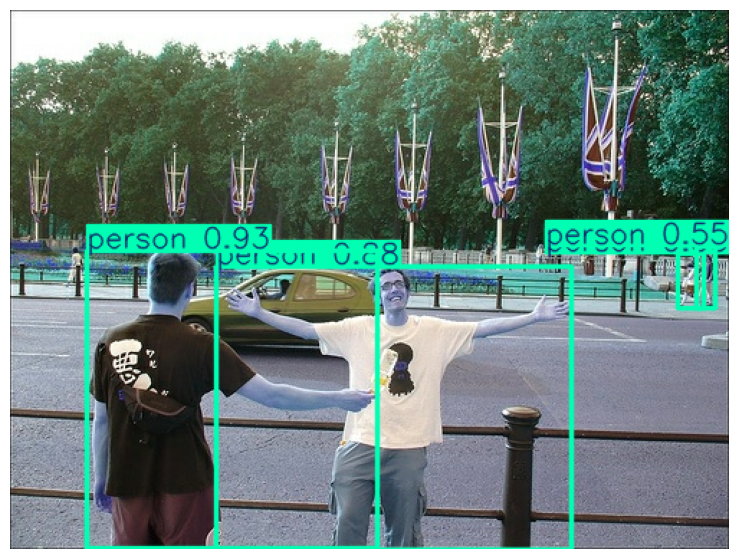


Image 3
Ground truth:
- tvmonitor
Predictions:
- tvmonitor: 92.67%


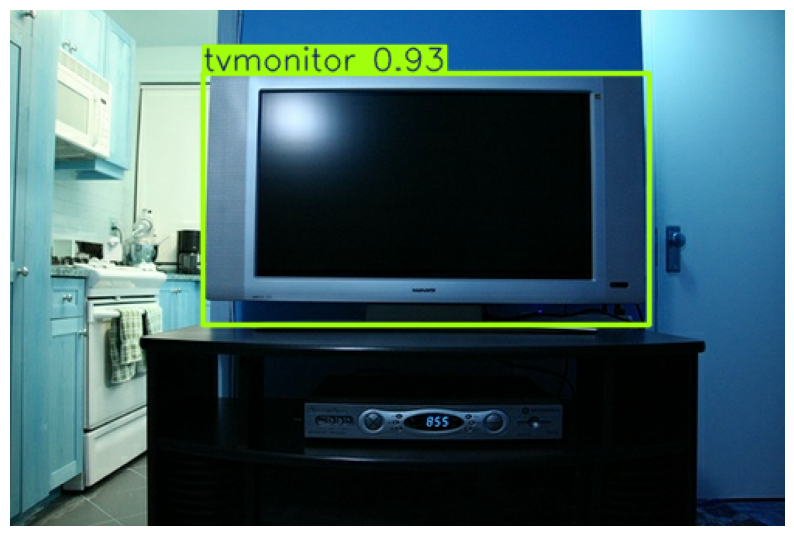


Image 4
Ground truth:
- dog
Predictions:
- sheep: 87.71%


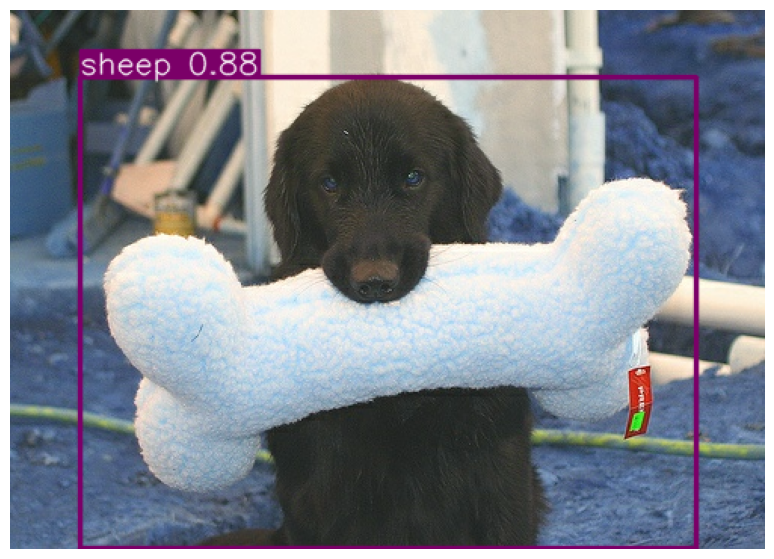


Image 5
Ground truth:
- diningtable
- person
- person
- person
Predictions:
- person: 94.81%
- person: 90.48%
- person: 53.89%
- diningtable: 50.27%
- person: 37.69%


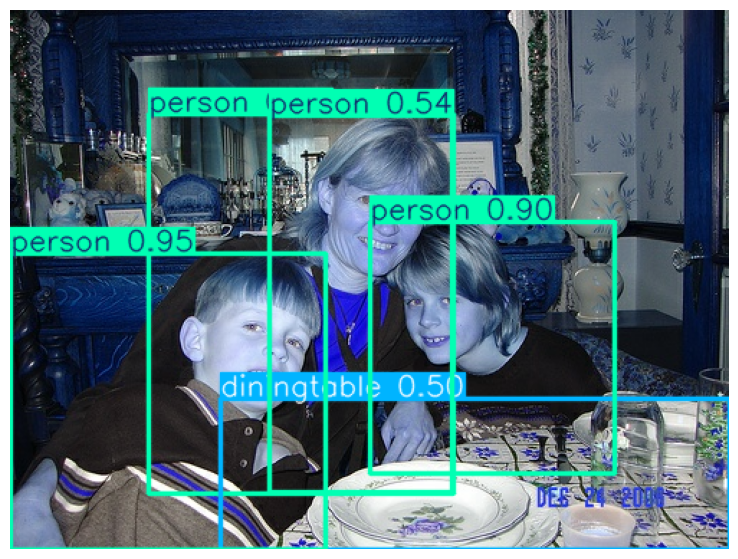

In [37]:
for i, sample in enumerate(datasets["test"].skip(1).take(4)):
    image = sample["image"].numpy()

    prediction = best_model.predict(
        source=image,
        imgsz=imgsz,
        conf=0.25,
        device=0,
        verbose=False
    )

    print(f"\nImage {i + 2}")
    print("Ground truth:")
    for label in sample["objects"]["label"].numpy():
        print("-", class_names[int(label)])

    print("Predictions:")
    for box in prediction[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(f"- {class_names[class_id]}: {confidence:.2%}")

    plt.figure(figsize=(10, 7))
    plt.imshow(prediction[0].plot()[..., ::-1])
    plt.axis("off")
    plt.show()

### 5.7 Analyze Training and Validation Losses


In [42]:
# Display the actual metric names saved during training
print(history.columns.tolist())

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


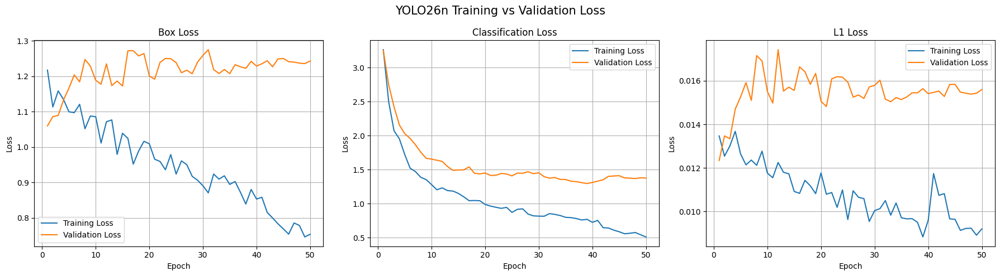

In [41]:
# Compare training and validation losses across epochs
loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box Loss"),
    ("train/cls_loss", "val/cls_loss", "Classification Loss"),
    ("train/l1_loss", "val/l1_loss", "L1 Loss")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (train_col, val_col, title) in zip(axes, loss_pairs):
    ax.plot(history["epoch"], history[train_col], label="Training Loss")
    ax.plot(history["epoch"], history[val_col], label="Validation Loss")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

plt.suptitle("YOLO26n Training vs Validation Loss", fontsize=15)
plt.tight_layout()
plt.show()

### 5.8 Analyze the Confusion Matrix


Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1347.5±274.8 MB/s, size: 39.5 KB)
val: Scanning /kaggle/working/voc_yolo/labels/val.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 28.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.9it/s 1.8s0.2s
                   all        100        334      0.753      0.632      0.713      0.513
             aeroplane          7          7      0.999      0.857      0.896       0.69
               bicycle          8         11       0.92          1      0.995      0.735
                  bird         10         17          1      0.452      0.537      0.443
                  boat          9         18      0.776        0.5      0.656      0.423
                bottle          5    

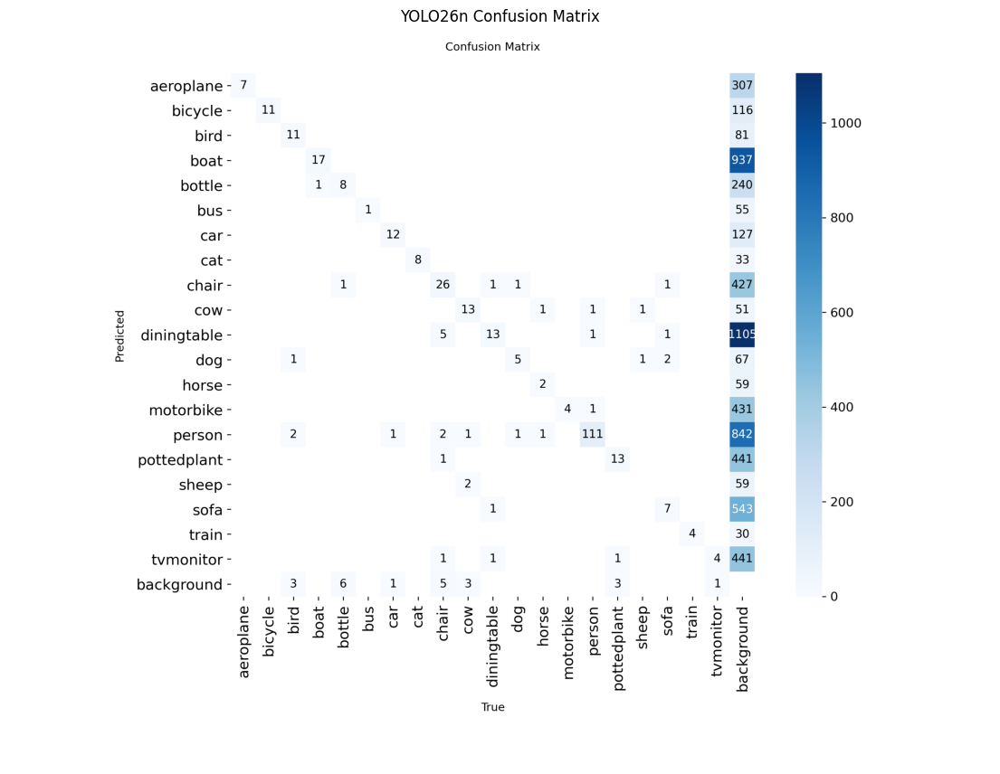

In [43]:
# Display the confusion matrix
metrics = best_model.val(
    data=str(dataset_path / "data.yaml"),
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    plots=True
)

confusion_matrix_path = Path(metrics.save_dir) / "confusion_matrix.png"

confusion_matrix_image = plt.imread(confusion_matrix_path)

plt.figure(figsize=(14, 12))
plt.imshow(confusion_matrix_image)
plt.axis("off")
plt.title("YOLO26n Confusion Matrix")
plt.show()

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 987.0±353.2 MB/s, size: 25.7 KB)
val: Scanning /kaggle/working/voc_yolo/labels/val.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100 32.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 3.9it/s 1.8s0.2s
                   all        100        334      0.788       0.62      0.597      0.441
             aeroplane          7          7          1      0.857      0.855      0.665
               bicycle          8         11       0.92          1      0.995      0.735
                  bird         10         17          1      0.412      0.415      0.369
                  boat          9         18      0.776        0.5      0.484      0.334
                bottle          5     

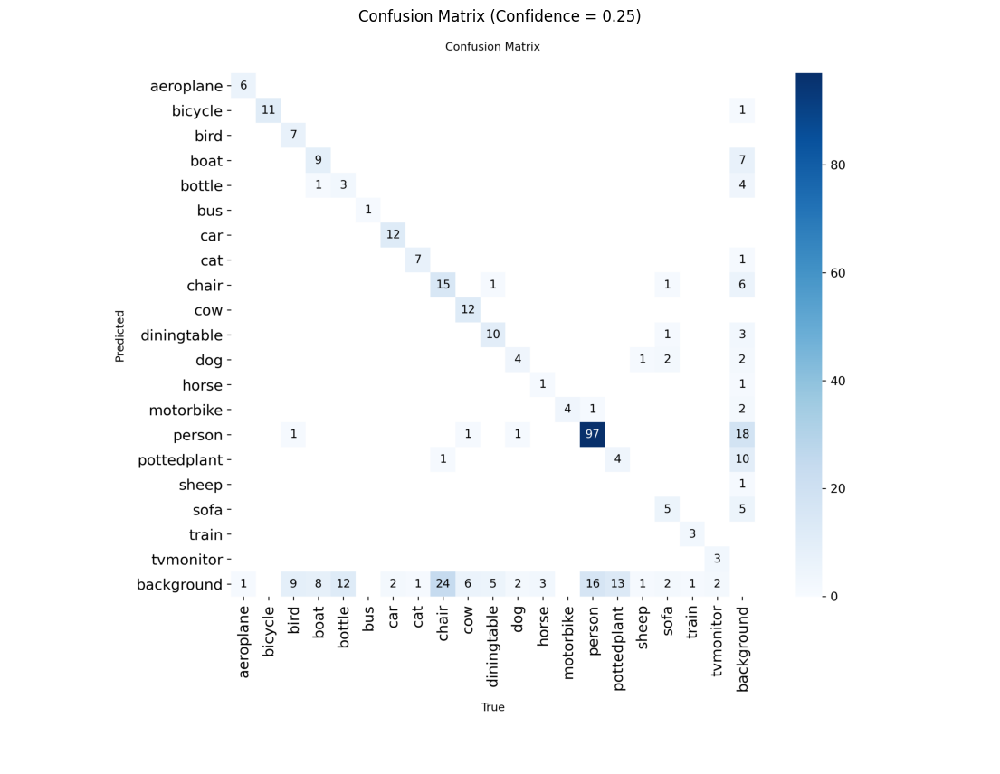

In [44]:
# Generate a confusion matrix with a 0.25 confidence threshold
matrix_metrics = best_model.val(
    data=str(dataset_path / "data.yaml"),
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    conf=0.25,
    plots=True,
    name="confusion_matrix_025"
)

# Display the new confusion matrix
matrix_path = Path(matrix_metrics.save_dir) / "confusion_matrix.png"

plt.figure(figsize=(14, 12))
plt.imshow(plt.imread(matrix_path))
plt.axis("off")
plt.title("Confusion Matrix (Confidence = 0.25)")
plt.show()

# 6.Full Dataset Preparation 


### 6.1 Create folders for the full dataset


In [45]:
# Create folders for the full dataset
dataset_path = Path("voc_yolo_full")

for split in ["train", "val"]:
    (dataset_path / "images" / split).mkdir(parents=True, exist_ok=True)
    (dataset_path / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Full dataset folders created successfully!")

Full dataset folders created successfully!


### 6.2 Convert the Full Dataset to YOLO Format


In [46]:
# Convert all training and validation samples
full_train_dataset = list(datasets["train"])
full_validation_dataset = list(datasets["validation"])

save_yolo_data(full_train_dataset, "train")
save_yolo_data(full_validation_dataset, "val")

print("Full dataset conversion completed!")
print("Training images:", len(full_train_dataset))
print("Validation images:", len(full_validation_dataset))

Full dataset conversion completed!
Training images: 2501
Validation images: 2510


### 6.3 Create the Dataset Configuration File


In [47]:
# Configure the full dataset
data_config = {
    'path': str(dataset_path.resolve()),
    'train': 'images/train',
    'val': 'images/val',
    'nc': len(class_names),
    'names': class_names
}

# Save the configuration file
with open(dataset_path / 'data.yaml', 'w') as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("Full dataset configuration created successfully!")

Full dataset configuration created successfully!


### 6.4 Verify the Full Dataset


In [48]:
# Verify the full dataset
for split in ["train", "val"]:
    image_count = len(list((dataset_path / "images" / split).glob("*.jpg")))
    label_count = len(list((dataset_path / "labels" / split).glob("*.txt")))

    print(f"{split.capitalize()} images: {image_count}")
    print(f"{split.capitalize()} labels: {label_count}")

print("Number of classes:", len(class_names))
print("Configuration file exists:", (dataset_path / "data.yaml").exists())

Train images: 2501
Train labels: 2501
Val images: 2510
Val labels: 2510
Number of classes: 20
Configuration file exists: True


# 7. Train YOLO26n on the Full Dataset


### 7.1 Load the Pretrained YOLO26n Model


In [49]:
# Load the pretrained YOLO26n model
full_model = YOLO("yolo26n.pt")

print("Pretrained YOLO26n model loaded successfully!")

Pretrained YOLO26n model loaded successfully!


### 7.2 Configure Full-Dataset Training Parameters

In [51]:
# Configure full-dataset training parameters
epochs = 100
imgsz = 640
batch_size = 16
patience = 15

print("Training parameters configured!")
print("Epochs:", epochs)
print("Image size:", imgsz)
print("Batch size:", batch_size)
print("Early stopping patience:", patience)

Training parameters configured!
Epochs: 100
Image size: 640
Batch size: 16
Early stopping patience: 15


### 7.3 Train YOLO26n on the Full Dataset

In [52]:
# Train YOLO26n on the full dataset
full_results = full_model.train(
    data=str(dataset_path / "data.yaml"),
    epochs=epochs,
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    patience=patience,
    project="runs",
    name="yolo26n_voc_full"
)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=voc_yolo_full/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_voc_full, nbs=64, nms=None, opset=None, optimize=False, 

### 7.4 Load the Best Full-Dataset Model

Load the best checkpoint saved during training for further evaluation and testing.

In [53]:
# Load the best model from full-dataset training
full_best_model = YOLO(
    str(Path(full_results.save_dir) / "weights" / "best.pt")
)

print("Best full-dataset model loaded successfully!")

Best full-dataset model loaded successfully!


### 7.5 Evaluate the Best Model


In [54]:
# Evaluate the best full-dataset model
full_metrics = full_best_model.val(
    data=str(dataset_path / "data.yaml"),
    imgsz=imgsz,
    batch=batch_size,
    device=0
)

print("Full-dataset evaluation completed!")
print("Precision:", full_metrics.box.mp)
print("Recall:", full_metrics.box.mr)
print("mAP50:", full_metrics.box.map50)
print("mAP50-95:", full_metrics.box.map)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1334.3±401.6 MB/s, size: 34.6 KB)
val: Scanning /kaggle/working/voc_yolo_full/labels/val.cache... 2510 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2510/2510 809.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 157/157 8.3it/s 19.0s0.2s
                   all       2510       7818      0.761      0.669      0.739      0.519
             aeroplane        127        175       0.88      0.753      0.858      0.598
               bicycle        133        216      0.772       0.69      0.768      0.531
                  bird        151        305      0.769      0.534      0.624      0.417
                  boat        101        190      0.605      0.669       0.67      0.416
                bottle 

### 7.6 Visualize Training Results


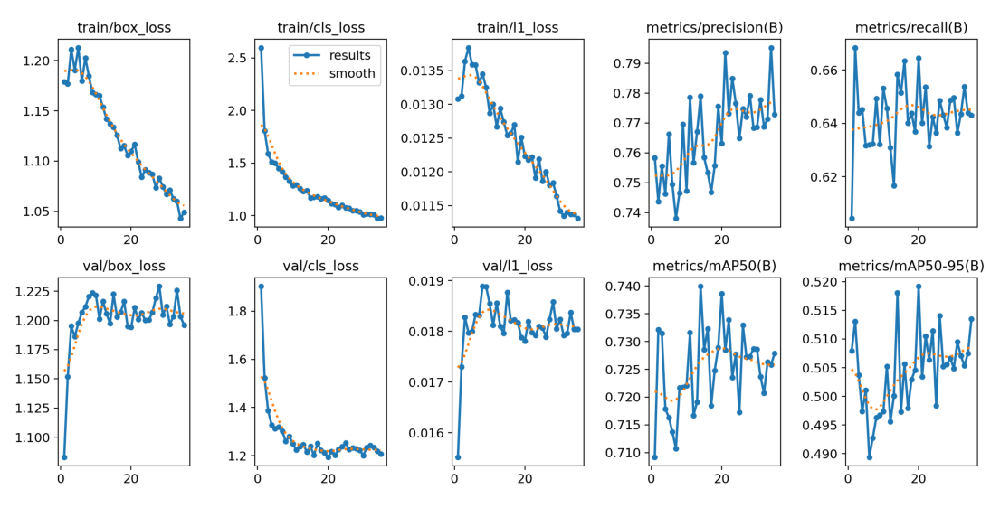

In [55]:
# Display the full-dataset training results
results_image = plt.imread(Path(full_results.save_dir) / "results.png")

plt.figure(figsize=(14, 10))
plt.imshow(results_image)
plt.axis("off")
plt.show()

### 7.7 Analyze Training and Validation Losses



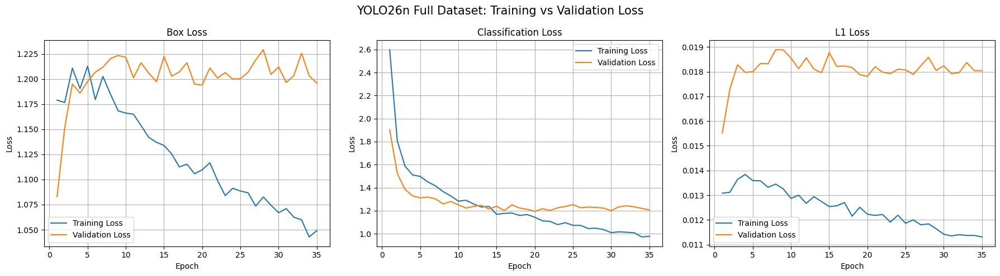

In [56]:
# Load training history
history = pd.read_csv(Path(full_results.save_dir) / "results.csv")

# Compare training and validation losses
loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box Loss"),
    ("train/cls_loss", "val/cls_loss", "Classification Loss"),
    ("train/l1_loss", "val/l1_loss", "L1 Loss")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (train_col, val_col, title) in zip(axes, loss_pairs):
    ax.plot(history["epoch"], history[train_col], label="Training Loss")
    ax.plot(history["epoch"], history[val_col], label="Validation Loss")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

plt.suptitle("YOLO26n Full Dataset: Training vs Validation Loss", fontsize=15)
plt.tight_layout()
plt.show()

### 7.8 Analyze the Confusion Matrix


Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1080.1±312.9 MB/s, size: 32.5 KB)
val: Scanning /kaggle/working/voc_yolo_full/labels/val.cache... 2510 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2510/2510 752.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 157/157 8.5it/s 18.5s0.1s
                   all       2510       7818      0.761      0.669      0.739      0.519
             aeroplane        127        175       0.88      0.753      0.858      0.598
               bicycle        133        216      0.772       0.69      0.768      0.531
                  bird        151        305      0.769      0.534      0.624      0.417
                  boat        101        190      0.605      0.669       0.67      0.416
                bottle 

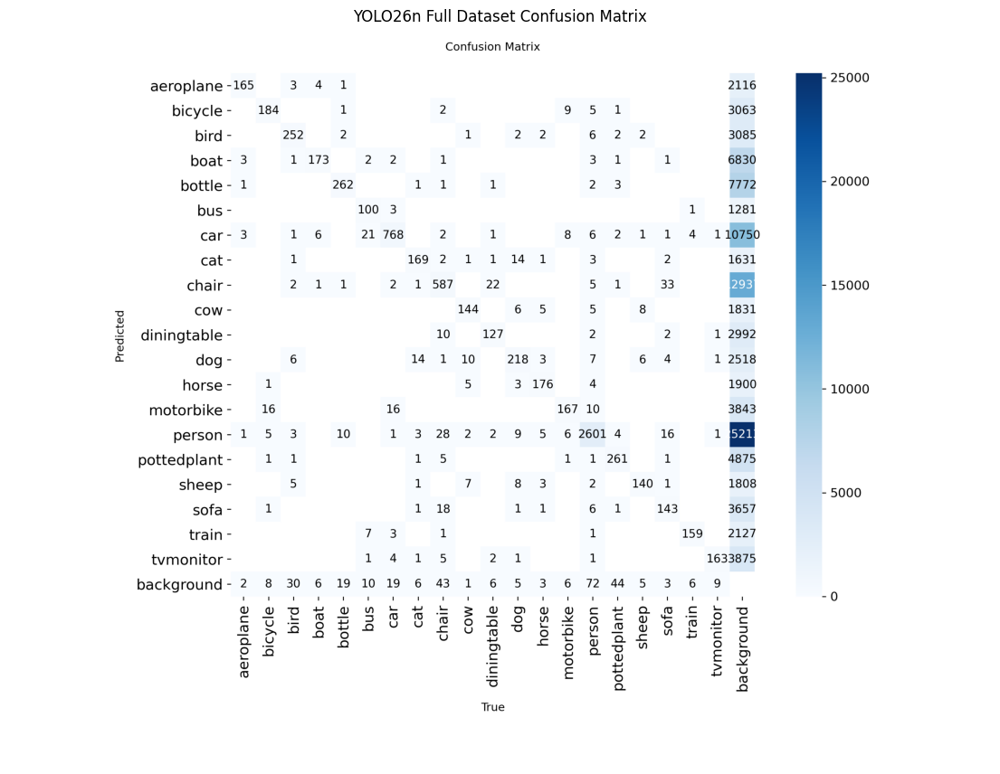

In [57]:
# Generate the confusion matrix
full_metrics = full_best_model.val(
    data=str(dataset_path / "data.yaml"),
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    plots=True
)

# Display the confusion matrix
confusion_matrix_path = Path(full_metrics.save_dir) / "confusion_matrix.png"
confusion_matrix_image = plt.imread(confusion_matrix_path)

plt.figure(figsize=(14, 12))
plt.imshow(confusion_matrix_image)
plt.axis("off")
plt.title("YOLO26n Full Dataset Confusion Matrix")
plt.show()

### 7.9 Generate a Confusion Matrix at Confidence 0.25


Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1083.8±433.1 MB/s, size: 32.2 KB)
val: Scanning /kaggle/working/voc_yolo_full/labels/val.cache... 2510 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2510/2510 752.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 157/157 8.8it/s 17.8s0.1s
                   all       2510       7818       0.76      0.669      0.645      0.464
             aeroplane        127        175       0.88      0.753      0.752      0.531
               bicycle        133        216      0.772       0.69      0.677      0.491
                  bird        151        305      0.769      0.535      0.509      0.355
                  boat        101        190      0.605       0.67      0.596      0.375
                bottle 

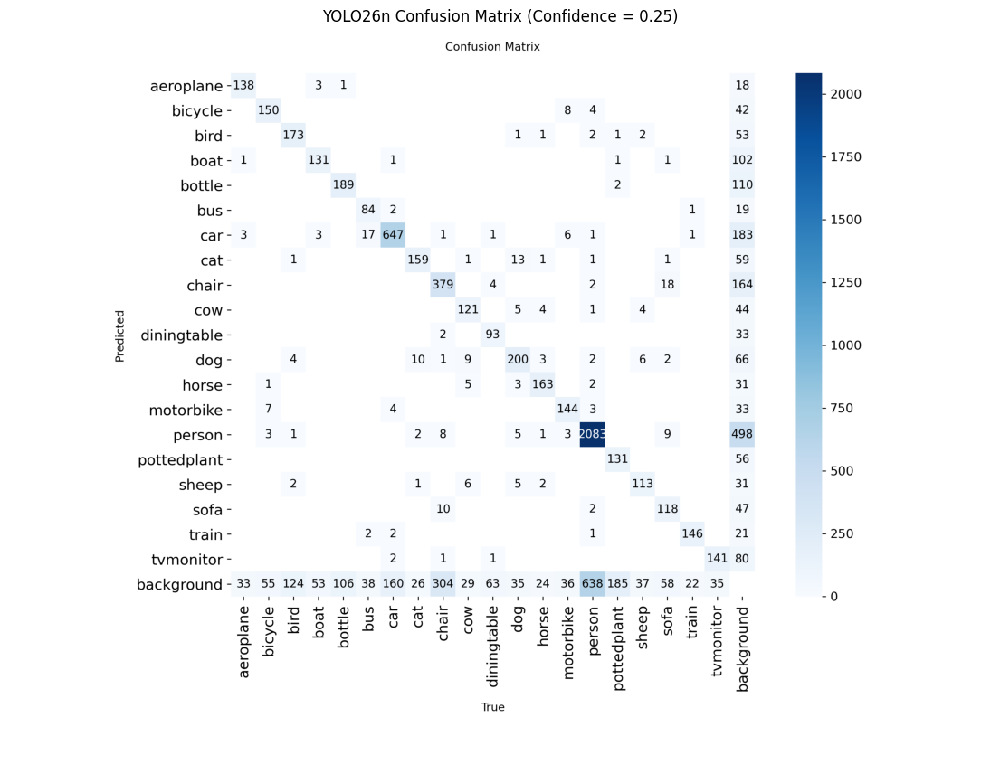

In [58]:
# Evaluate the model using a confidence threshold of 0.25
conf_metrics = full_best_model.val(
    data=str(dataset_path / "data.yaml"),
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    conf=0.25,
    plots=True
)

# Display the confusion matrix
conf_matrix_path = Path(conf_metrics.save_dir) / "confusion_matrix.png"
conf_matrix_image = plt.imread(conf_matrix_path)

plt.figure(figsize=(14, 12))
plt.imshow(conf_matrix_image)
plt.axis("off")
plt.title("YOLO26n Confusion Matrix (Confidence = 0.25)")
plt.show()

7.10 Generate a Normalized Confusion Matrix 

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 974.7±363.6 MB/s, size: 31.3 KB)
val: Scanning /kaggle/working/voc_yolo_full/labels/val.cache... 2510 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2510/2510 809.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 157/157 8.7it/s 18.0s<0.1s
                   all       2510       7818       0.76      0.669      0.645      0.464
             aeroplane        127        175       0.88      0.753      0.752      0.531
               bicycle        133        216      0.772       0.69      0.677      0.491
                  bird        151        305      0.769      0.535      0.509      0.355
                  boat        101        190      0.605       0.67      0.596      0.375
                bottle 

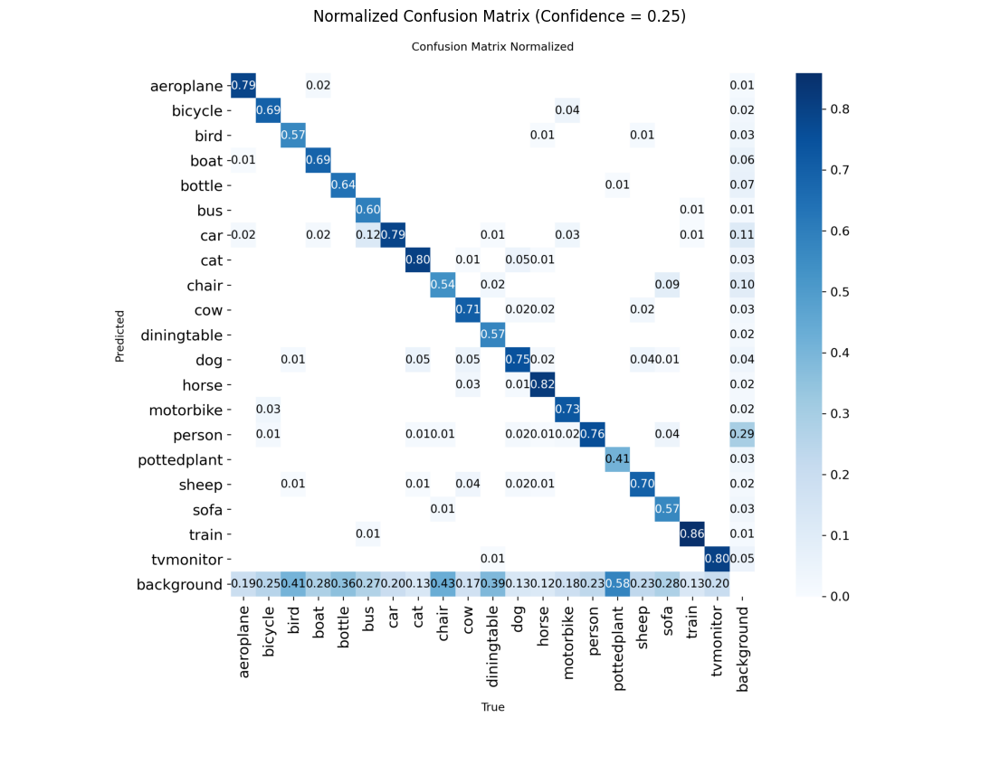

In [59]:
normalized_metrics = full_best_model.val(
    data=str(dataset_path / "data.yaml"),
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    conf=0.25,
    plots=True
)

# Display the normalized confusion matrix
normalized_cm_path = (
    Path(normalized_metrics.save_dir) / "confusion_matrix_normalized.png"
)

normalized_cm_image = plt.imread(normalized_cm_path)

plt.figure(figsize=(14, 12))
plt.imshow(normalized_cm_image)
plt.axis("off")
plt.title("Normalized Confusion Matrix (Confidence = 0.25)")
plt.show()

### 7.11 Analyze Per-Class Performance

Compare precision, recall, mAP50, and mAP50-95 across all 20 classes to identify the strongest and weakest object categories.

In [60]:
class_results = pd.DataFrame({
    "Class": class_names,
    "Precision": full_metrics.box.p,
    "Recall": full_metrics.box.r,
    "mAP50": full_metrics.box.ap50,
    "mAP50-95": full_metrics.box.ap
})

class_results = class_results.round(3)
class_results

,Class,Precision,Recall,mAP50,mAP50-95
0,aeroplane,0.880,0.753,0.858,0.598
1,bicycle,0.772,0.690,0.768,0.531
2,bird,0.769,0.534,0.624,0.417
3,boat,0.605,0.669,0.670,0.416
4,bottle,0.687,0.618,0.641,0.424
5,bus,0.853,0.618,0.730,0.609
6,car,0.769,0.752,0.815,0.592
7,cat,0.719,0.803,0.826,0.639
8,chair,0.698,0.495,0.583,0.381
9,cow,0.761,0.719,0.800,0.576


### 7.12 Full-Dataset Training Summary


In [61]:
training_summary = pd.DataFrame({
    "Metric": [
        "Model",
        "Dataset",
        "Training Images",
        "Validation Images",
        "Number of Classes",
        "Maximum Epochs",
        "Actual Epochs",
        "Image Size",
        "Batch Size",
        "Best Epoch",
        "Precision",
        "Recall",
        "mAP50",
        "mAP50-95"
    ],
    "Value": [
        "YOLO26n",
        "PASCAL VOC 2007",
        2501,
        2510,
        20,
        epochs,
        len(history),
        imgsz,
        batch_size,
        20,
        f"{full_metrics.box.mp:.3f}",
        f"{full_metrics.box.mr:.3f}",
        f"{full_metrics.box.map50:.3f}",
        f"{full_metrics.box.map:.3f}"
    ]
})

training_summary

,Metric,Value
0,Model,YOLO26n
1,Dataset,PASCAL VOC 2007
2,Training Images,2501
3,Validation Images,2510
4,Number of Classes,20
5,Maximum Epochs,100
6,Actual Epochs,35
7,Image Size,640
8,Batch Size,16
9,Best Epoch,20


# 8. Final Evaluation on the Test Dataset

### 8.1 Inspect the Test Dataset


In [62]:
# Check the size of the untouched PASCAL VOC 2007 test split before preparing it for final evaluation.
test_dataset = datasets["test"]

print("Number of test images:", len(test_dataset))

Number of test images: 4952


### 8.2 Prepare Test Dataset Folders

In [63]:
# Create folders for test images and labels
(dataset_path / "images" / "test").mkdir(parents=True, exist_ok=True)
(dataset_path / "labels" / "test").mkdir(parents=True, exist_ok=True)

print("Test dataset folders created successfully!")

Test dataset folders created successfully!


### 8.3 Convert Test Images and Annotations

In [64]:
# Convert all test images and annotations to YOLO format
full_test_dataset = list(test_dataset)
save_yolo_data(full_test_dataset, "test")

print("Test dataset conversion completed!")
print("Test images:", len(full_test_dataset))

Test dataset conversion completed!
Test images: 4952


### 8.4 Update the Dataset Configuration

In [65]:
# Add the test split to the dataset configuration
data_config["test"] = "images/test"

with open(dataset_path / "data.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("Dataset configuration updated successfully!")

Dataset configuration updated successfully!


### 8.5 Verify Test Dataset

In [66]:
# Check the number of test images and labels
test_images = list((dataset_path / "images" / "test").glob("*.jpg"))
test_labels = list((dataset_path / "labels" / "test").glob("*.txt"))

print("Test images:", len(test_images))
print("Test labels:", len(test_labels))
print("Test configuration:", data_config["test"])

Test images: 4952
Test labels: 4952
Test configuration: images/test


### 8.6 Evaluate the Model on the Test Dataset

In [67]:
# Evaluate the best model on the untouched test dataset
test_metrics = full_best_model.val(
    data=str(dataset_path / "data.yaml"),
    split="test",
    imgsz=imgsz,
    batch=batch_size,
    device=0,
    plots=True
)

print("Final test evaluation completed!")
print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP50:", test_metrics.box.map50)
print("mAP50-95:", test_metrics.box.map)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,394,352 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1346.0±438.0 MB/s, size: 44.4 KB)
val: Scanning /kaggle/working/voc_yolo_full/labels/test... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 1.1Kit/s 4.6s0.0s
val: New cache created: /kaggle/working/voc_yolo_full/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 8.7it/s 35.5s0.1ss
                   all       4952      14976      0.771      0.652      0.726      0.508
             aeroplane        205        311      0.821      0.756      0.831      0.579
               bicycle        250        389      0.829      0.702      0.787      0.559
                  bird        289        576       0.77      0.575      0.674      0.442
                  boat        176        3

### 8.7 Analyze Per-Class Test Performance

In [68]:
# Compare test performance across all 20 classes
test_class_results = pd.DataFrame({
    "Class": class_names,
    "Precision": test_metrics.box.p,
    "Recall": test_metrics.box.r,
    "mAP50": test_metrics.box.ap50,
    "mAP50-95": test_metrics.box.ap
})

test_class_results = test_class_results.round(3)
test_class_results

,Class,Precision,Recall,mAP50,mAP50-95
0,aeroplane,0.821,0.756,0.831,0.579
1,bicycle,0.829,0.702,0.787,0.559
2,bird,0.770,0.575,0.674,0.442
3,boat,0.618,0.519,0.564,0.330
4,bottle,0.682,0.496,0.566,0.354
5,bus,0.880,0.661,0.778,0.641
6,car,0.817,0.766,0.843,0.619
7,cat,0.742,0.805,0.787,0.594
8,chair,0.725,0.459,0.575,0.358
9,cow,0.762,0.745,0.783,0.522


### 8.8 Visualize Predictions on Test Images


0: 640x640 2 trains, 5.1ms
1: 640x640 1 cat, 1 horse, 5.1ms
2: 640x640 1 bird, 5.1ms
3: 640x640 2 bottles, 1 chair, 1 diningtable, 4 persons, 5.1ms
4: 640x640 1 cat, 1 chair, 1 pottedplant, 3 tvmonitors, 5.1ms
5: 640x640 1 car, 1 person, 5.1ms
Speed: 1.6ms preprocess, 5.1ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)


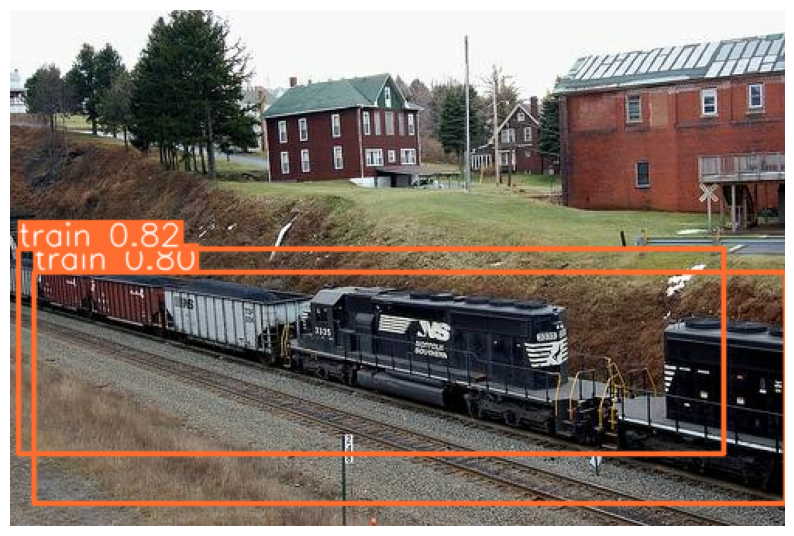

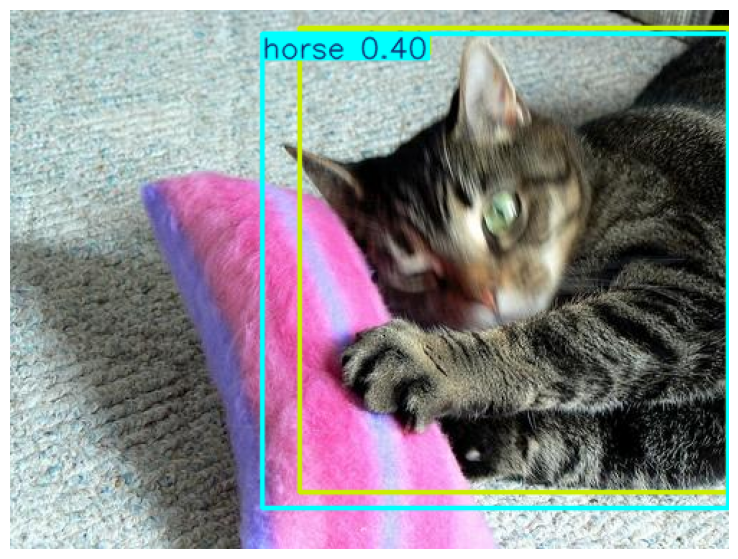

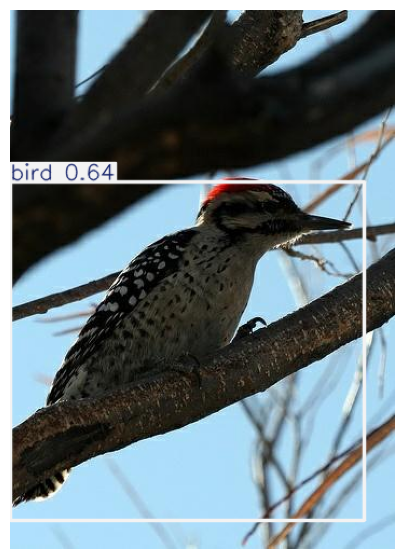

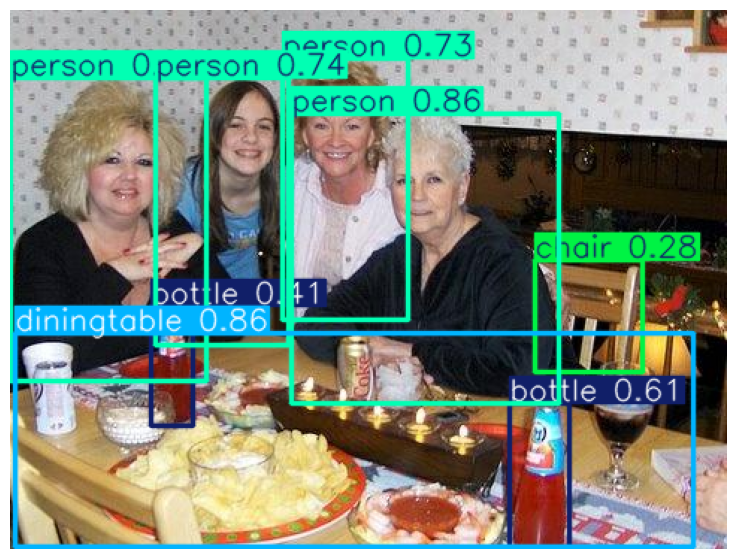

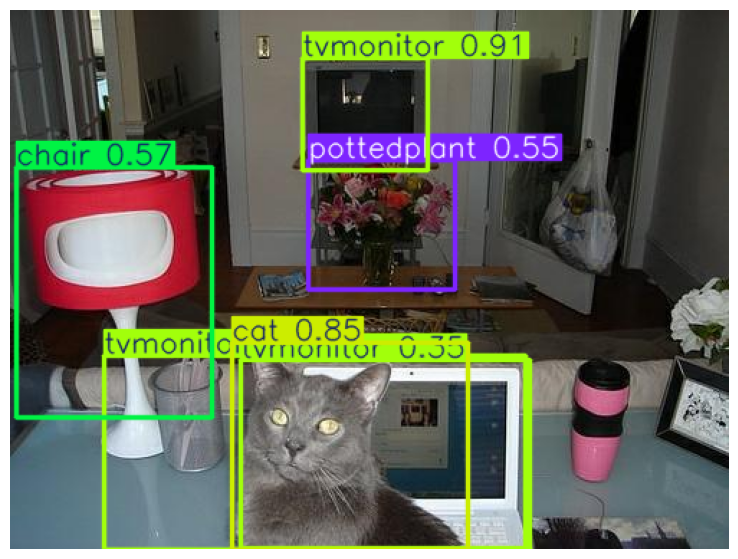

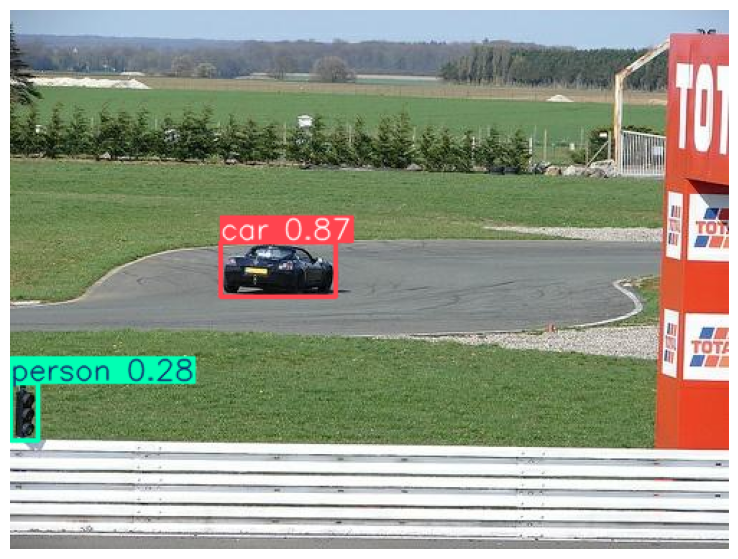

In [69]:
# Select test images and visualize model predictions
test_image_paths = sorted(
    (dataset_path / "images" / "test").glob("*.jpg")
)

sample_images = random.sample(test_image_paths, 6)

test_predictions = full_best_model.predict(
    source=[str(path) for path in sample_images],
    imgsz=imgsz,
    conf=0.25,
    device=0
)

for result in test_predictions:
    plt.figure(figsize=(10, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.show()

### 8.9 Final Model Evaluation Summary

In [70]:
# Compare validation and test performance
final_comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "mAP50", "mAP50-95"],
    "Validation": [
        full_metrics.box.mp,
        full_metrics.box.mr,
        full_metrics.box.map50,
        full_metrics.box.map
    ],
    "Test": [
        test_metrics.box.mp,
        test_metrics.box.mr,
        test_metrics.box.map50,
        test_metrics.box.map
    ]
})

final_comparison = final_comparison.round(3)
final_comparison

,Metric,Validation,Test
0,Precision,0.761,0.771
1,Recall,0.669,0.652
2,mAP50,0.739,0.726
3,mAP50-95,0.519,0.508


# 9. Save and Backup Project

### 9.1 Create a Complete Backup

In [82]:
backup_dir = Path("/kaggle/working/yolo26n_backup")
backup_dir.mkdir(parents=True, exist_ok=True)

# Save the full training run and model weights
shutil.copytree(
    Path(full_results.save_dir),
    backup_dir / "training_run",
    dirs_exist_ok=True
)

# Save validation and test results
shutil.copytree(
    Path(full_metrics.save_dir),
    backup_dir / "validation_results",
    dirs_exist_ok=True
)

shutil.copytree(
    Path(test_metrics.save_dir),
    backup_dir / "test_results",
    dirs_exist_ok=True
)

# Save the converted dataset
shutil.copytree(
    dataset_path,
    backup_dir / "voc_yolo_full",
    dirs_exist_ok=True
)

# Create a ZIP archive
backup_zip = shutil.make_archive(
    "/kaggle/working/yolo26n_backup",
    "zip",
    root_dir=backup_dir
)

print("Backup created successfully!")
print("Backup location:", backup_zip)

Backup created successfully!
Backup location: /kaggle/working/yolo26n_backup.zip


### 9.2 Verify Backup

In [83]:
backup_size = os.path.getsize(backup_zip) / (1024 ** 3)

print("Backup exists:", os.path.exists(backup_zip))
print(f"Backup size: {backup_size:.2f} GB")

Backup exists: True
Backup size: 0.35 GB
